### Cell 0: Environment Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
np.random.seed(42)

### Cell 1: Environment Setup & Approved PD Master Scale

In [2]:
# Define global facility population size (Simulating a full 50,000 commercial loan book)
N_FACILITIES = 50_000

# IFRS 9 Multi-Scenario Probability Weightings approved by Provisioning Committee:
# - Base Case (50%): Central economic forecast based on RBA baseline.
# - Downside Case (40%): Severe macro stress (cash rate hikes, property value drops).
# - Upside Case (10%): Favorable economic tailwinds.
MACRO_WEIGHTS = {'Base': 0.50, 'Upside': 0.10, 'Downside': 0.40}

# 24-Grade Master Scale (Through-The-Cycle / TTC PD Lookup Table)
# Maps internal Customer Risk Grades (CRG 1 to 24) to long-run historical baseline PDs.
# - CRG 1 to 10: Investment Grade / Strong (0.03% to 1.10% PD)
# - CRG 11 to 16: Pass / Satisfactory (1.60% to 10.00% PD)
# - CRG 17 to 23: Watchlist & Weak (14.50% to 82.00% PD)
# - CRG 24: Default / Credit Impaired (100.00% PD)
PD_MASTER_SCALE = {
    1: 0.0003,  2: 0.0005,  3: 0.0008,  4: 0.0012,  5: 0.0018,  6: 0.0025,
    7: 0.0035,  8: 0.0050,  9: 0.0075, 10: 0.0110, 11: 0.0160, 12: 0.0230,
    13: 0.0330, 14: 0.0480, 15: 0.0700, 16: 0.1000, 17: 0.1450, 18: 0.2000,
    19: 0.2800, 20: 0.3800, 21: 0.5000, 22: 0.6500, 23: 0.8200, 24: 1.0000
}

print(f"Environment initialized for N = {N_FACILITIES:,} commercial facilities using the 24-Grade Master Scale.")

Environment initialized for N = 50,000 commercial facilities using the 24-Grade Master Scale.


### Cell 2: Synthetic Business Banking Portfolio Generation ($t, t+1, t+2$)

In [3]:
# ------------------------------------------------------------------------------
# 1. FACILITY IDENTIFIERS, METADATA & GL ACCOUNT MAPPING
# ------------------------------------------------------------------------------

# Generate unique string identifiers for every commercial loan facility (e.g., BUS_000001)
facility_ids = [f"BUS_{i+1:06d}" for i in range(N_FACILITIES)]

# Assign industry sectors
# - Commercial Real Estate (35%): Income-producing property & development debt
# - Corporate (30%): Large commercial term loans & revolving credit
# - SME Retail (20%): Small-business working capital and equipment facilities
# - Agribusiness (15%): Agricultural term debt vulnerable to climate shocks
sectors = np.random.choice(
    ['Commercial Real Estate', 'Agribusiness', 'Corporate', 'SME Retail'], 
    size=N_FACILITIES, 
    p=[0.35, 0.15, 0.30, 0.20]
)

# Conditional GL Account mapping function aligned with product types
def map_gl_account(sector):
    if sector in ['Commercial Real Estate', 'Corporate']:
        # CRE and Corporate facilities are 100% commercial term loans
        return 'GL_1010_COMMERCIAL'
    elif sector == 'Agribusiness':
        # Agribusiness holds term debt for land/property, plus equipment lines for tractors/machinery
        return np.random.choice(['GL_1010_COMMERCIAL', 'GL_1020_EQUIP_FIN'], p=[0.75, 0.25])
    else:  # SME Retail
        # SME working capital loans vs specialized equipment finance
        return np.random.choice(['GL_1010_COMMERCIAL', 'GL_1020_EQUIP_FIN'], p=[0.60, 0.40])

# Map facilities to primary General Ledger asset sub-ledger codes
gl_accounts = [map_gl_account(s) for s in sectors]

# ------------------------------------------------------------------------------
# 2. CREDIT LIMITS, BALANCES & EXPOSURE AT DEFAULT (EAD)
# ------------------------------------------------------------------------------
# Generate total approved credit limits using a Lognormal distribution (most between $100k to $10M+)
approved_limits = np.random.lognormal(mean=13.0, sigma=1.2, size=N_FACILITIES)

# Simulate current drawn loan principal balances as a percentage (40% to 95%) of approved limits
drawn_balances = approved_limits * np.random.uniform(0.40, 0.95, size=N_FACILITIES)

# Calculate committed undrawn facility headrooms available for borrower drawdown
undrawn_balances = approved_limits - drawn_balances

# Apply Credit Conversion Factors (CCF):
# - Corporate revolving credit/lines: 50% CCF (assumes 50% of undrawn headroom is drawn prior to default)
# - Non-revolving term loans: 75% CCF
# Simplified assumption:
# Corporate facilities assume 50% utilization of available commitments prior to default.
# Other business banking facilities assume 75% utilization.
ccf = np.where(sectors == 'Corporate', 0.50, 0.75) # considering simplified case for sake of project and not full drawn or disbursed non-revolving term loans etc.

# Exposure at Default (EAD) formula: EAD = Drawn Balance + (Undrawn Limit * CCF)
ead_values = drawn_balances + (undrawn_balances * ccf)

#------------------------------------------------------------------------------------
### Adverse DPD MIGRATION and Credit Risk Grade (CRG) Migration are SICR (Stage 2) Triggers, which we will define later.
# -----------------------------------------------------------------------------------

# ------------------------------------------------------------------------------
# 3. CUSTOMER RISK GRADE (CRG) MIGRATION OR RATING MIGRATION ACROSS TIME HORIZONS .. during quaretly, half-yearly or annual reviews of accounts
# ------------------------------------------------------------------------------
# Generate initial Customer Risk Grades at origination (CRG 1 to 19)
crg_orig = np.random.choice(np.arange(1, 20), size=N_FACILITIES)

# Simulate CRG at Current Month (t) by applying rating migrations to origination grades:
# - 78% probability: No change (Grade remains constant)
# - 10% probability: Upgrade (-1 grade)
# - 8% probability: Minor downgrade (+1 grade)
# - 3% probability: Moderate downgrade (+3 grades -> Triggers SICR / Stage 2)
# - 1% probability: Severe downgrade (+6 grades -> Triggers Default / Stage 3). Logic is if UTP (Unlikely to Pay), then considered as default, even if  CRG is less than 24.
crg_t = np.clip(crg_orig + np.random.choice([-1, 0, 1, 3, 6], size=N_FACILITIES, p=[0.10, 0.78, 0.08, 0.03, 0.01]), 1, 24)

# Simulate CRG at Forecast """"Year 1""""" (t+1) for multi-period outlook .. i.e. after 12 months 
crg_t1 = np.clip(crg_t + np.random.choice([-1, 0, 1, 3, 5], size=N_FACILITIES, p=[0.05, 0.84, 0.08, 0.02, 0.01]), 1, 24)

# Simulate CRG at Forecast """""Year 2""""" (t+2) for multi-period outlook i.e. after 24 months
crg_t2 = np.clip(crg_t1 + np.random.choice([-1, 0, 1, 2], size=N_FACILITIES, p=[0.05, 0.88, 0.05, 0.02]), 1, 24)

# ------------------------------------------------------------------------------
# 4. DELINQUENCY, CONTRACTUAL & PRIOR PROVISION ATTRIBUTES .. payment behaviour and other behaviours
# ------------------------------------------------------------------------------
# Days Past Due (DPD) status at current period t (88% current, 1% defaulted >= 90 DPD)
dpd_t = np.random.choice([0, 15, 30, 60, 90], size=N_FACILITIES, p=[0.88, 0.05, 0.04, 0.02, 0.01])

# Automatically set DPD to 90 if the facility's CRG degraded to 24 (Default) in future periods
dpd_t1 = np.where(crg_t1 == 24, 90, dpd_t)
dpd_t2 = np.where(crg_t2 == 24, 90, dpd_t1)

# Effective Interest Rates (EIR) used for discounting expected future expected credit losses (i.e. future remaining cash shortfalls bank doesn't recover from borrower after recoveries)
# Discounted to their present value (4.0% to 9.0%)
eir = np.random.uniform(0.04, 0.09, size=N_FACILITIES)

# Remaining loan term in years (1 to 10 years) used for lifetime ECL discounting
term_years = np.random.randint(1, 10, size=N_FACILITIES)

# Disable scientific notation and show normal numbers
pd.options.display.float_format = '{:,.2f}'.format

# Assemble core variables into a primary Pandas DataFrame
df = pd.DataFrame({
    'Facility_ID': facility_ids, 'Sector': sectors, 'GL_Account': gl_accounts,
    'Drawn_Balance': drawn_balances, 'Undrawn_Balance': undrawn_balances, 'CCF': ccf, 'EAD': ead_values,
    'CRG_Orig': crg_orig, 'CRG_t': crg_t, 'CRG_t1': crg_t1, 'CRG_t2': crg_t2,
    'DPD_t': dpd_t, 'DPD_t1': dpd_t1, 'DPD_t2': dpd_t2,
    'Historical_LGD': np.random.uniform(0.25, 0.55, size=N_FACILITIES), # Unsecured loss severity (25% to 55%)
    'EIR': eir, 
    'Term_Years': term_years,
    'Prior_ECL': ead_values * 0.005 # Baseline t-1 balance sheet ECL reserve held last month # I guess roughly for simplicity assume PD % * LGD %  = 0.005 constant for all loans.
})

# Can calculate Current ECL, Current Stage and Current Provisions without Prior ECL.
# Need Prior ECL to calculate Loan Impairment Expense, Provision movement, Variance attribution, Opening vs Closing Provision, Executive roll-forward
# Prior ECL gotten from Previous month-end provisioning run

# Display preview of top 5 generated facilities
# display(df[['Facility_ID', 'Sector', 'EAD', 'CRG_Orig', 'CRG_t', 'CRG_t1', 'CRG_t2']].head())
display(df.head(10))

,Facility_ID,Sector,GL_Account,Drawn_Balance,Undrawn_Balance,CCF,EAD,CRG_Orig,CRG_t,CRG_t1,CRG_t2,DPD_t,DPD_t1,DPD_t2,Historical_LGD,EIR,Term_Years,Prior_ECL
0,BUS_000001,Agribusiness,GL_1020_EQUIP_FIN,"178,331.03","48,666.56",0.75,"214,830.96",9,9,9,9,0,0,0,0.32,0.08,6,"1,074.15"
1,BUS_000002,SME Retail,GL_1010_COMMERCIAL,"437,822.60","123,825.46",0.75,"530,691.70",4,4,4,4,30,30,30,0.49,0.07,5,"2,653.46"
2,BUS_000003,Corporate,GL_1010_COMMERCIAL,"18,534.85","21,320.81",0.50,"29,195.25",2,2,2,1,0,0,0,0.31,0.09,6,145.98
3,BUS_000004,Corporate,GL_1010_COMMERCIAL,"726,805.55","129,929.43",0.50,"791,770.26",3,2,2,2,0,0,0,0.47,0.05,7,"3,958.85"
4,BUS_000005,Commercial Real Estate,GL_1010_COMMERCIAL,"272,245.24","155,412.21",0.75,"388,804.40",17,18,19,19,0,0,0,0.34,0.04,8,"1,944.02"
5,BUS_000006,Commercial Real Estate,GL_1010_COMMERCIAL,"361,224.90","476,319.60",0.75,"718,464.60",16,16,16,16,0,0,0,0.53,0.08,6,"3,592.32"
6,BUS_000007,Commercial Real Estate,GL_1010_COMMERCIAL,"236,152.23","94,986.80",0.75,"307,392.33",13,13,14,14,0,0,0,0.41,0.07,4,"1,536.96"
7,BUS_000008,SME Retail,GL_1010_COMMERCIAL,"144,766.57","16,275.88",0.75,"156,973.48",1,1,1,1,0,0,0,0.34,0.05,4,784.87
8,BUS_000009,Corporate,GL_1010_COMMERCIAL,"414,984.58","92,554.57",0.50,"461,261.86",9,9,10,9,0,0,0,0.46,0.06,9,"2,306.31"
9,BUS_000010,Corporate,GL_1010_COMMERCIAL,"678,672.27","777,585.27",0.50,"1,067,464.90",6,6,5,6,0,0,0,0.49,0.06,1,"5,337.32"


### Cell 3: GL Reconciliation & Executive Exception Dashboard

#### This is unnecessary operation. Ignore.

In [4]:
# ------------------------------------------------------------------------------
# 1. SUB-LEDGER GL RECONCILIATION & ANOMALY INJECTION
# ------------------------------------------------------------------------------
# Copy actual drawn principal balances to represent sub-ledger account extracts i.e. assume balance of Finance GL and Credit Risk system matches
df['GL_Sub_Ledger_Balance'] = df['Drawn_Balance']

# Inject deliberate out-of-balance breaks in 7 random facilities to test control checks
break_indices = np.random.choice(df.index, size=7, replace=False)
df.loc[break_indices, 'GL_Sub_Ledger_Balance'] += np.random.uniform(15000, 200000, size=7) #Change Finance GL value for 7 loan facilities. Artificial modification to test the system.

# Calculate dollar variance between General Ledger balances and credit engine drawn balances
df['GL_Variance'] = df['GL_Sub_Ledger_Balance'] - df['Drawn_Balance']   # Each loan facility's values compared

# Count total reconciliation breaks where GL Variance is non-zero
total_gl_breaks = (df['GL_Variance'] != 0).sum()

# Identify Watchlist facilities (CRG 17 to 23) requiring heightened credit monitoring
watchlist_accounts = ((df['CRG_t'] >= 17) & (df['CRG_t'] <= 23)).sum() # Gets total number of watchlist_accounts

# ------------------------------------------------------------------------------
# 2. IDENTIFY DISCREPANCIES
# ------------------------------------------------------------------------------

# Identify facilities with GL reconciliation breaks
gl_breaks = df.loc[
    df['GL_Variance'].abs() > 0.01,
    [
        'Drawn_Balance',
        'GL_Sub_Ledger_Balance',
        'GL_Variance',
        'EAD',
        'CRG_t'
    ]
].copy()

# Rank breaks by absolute dollar variance
gl_breaks['Absolute_Variance'] = gl_breaks['GL_Variance'].abs()

gl_breaks = gl_breaks.sort_values(
    'Absolute_Variance',
    ascending=False
)

display(gl_breaks)

# ------------------------------------------------------------------------------
# 3. EXECUTIVE EXCEPTION CONTROL DASHBOARD
# ------------------------------------------------------------------------------

# Build high-level control exception summary table for operational risk reporting
exception_summary = pd.DataFrame({
    'Control Metric': [
        'Total Sub-Ledger GL Breaks', 
        'Watchlist Facilities (CRG 17-23)', 
        'Defaulted Facilities (CRG 24)'
    ],
    'Facility Count': [
        total_gl_breaks, 
        watchlist_accounts, 
        (df['CRG_t'] == 24).sum()
    ],
    'Exposed EAD ($M)': [
        df[df['GL_Variance'] != 0]['EAD'].sum() / 1e6,
        df[(df['CRG_t'] >= 17) & (df['CRG_t'] <= 23)]['EAD'].sum() / 1e6,
        df[df['CRG_t'] == 24]['EAD'].sum() / 1e6
    ]
})

print("--- CONTROLS & EXECUTIVE EXCEPTION DASHBOARD ---")
display(exception_summary.style.format({'Exposed EAD ($M)': "${:,.2f}"}))

,Drawn_Balance,GL_Sub_Ledger_Balance,GL_Variance,EAD,CRG_t,Absolute_Variance
27971,"2,188,558.22","2,369,308.17","180,749.96","3,628,071.16",14,"180,749.96"
21166,"223,768.37","390,461.64","166,693.27","293,477.95",4,"166,693.27"
10762,"695,331.34","821,998.15","126,666.81","820,559.86",10,"126,666.81"
13284,"230,627.67","352,002.24","121,374.57","247,295.52",4,"121,374.57"
34627,"2,165,555.63","2,247,534.34","81,978.71","2,636,045.26",14,"81,978.71"
48933,"109,656.77","170,278.65","60,621.88","164,407.73",3,"60,621.88"
13723,"428,821.65","480,616.10","51,794.45","727,376.93",10,"51,794.45"


--- CONTROLS & EXECUTIVE EXCEPTION DASHBOARD ---


,Control Metric,Facility Count,Exposed EAD ($M)
0,Total Sub-Ledger GL Breaks,7,$8.52
1,Watchlist Facilities (CRG 17-23),8169,"$6,557.05"
2,Defaulted Facilities (CRG 24),51,$32.45


### Cell 4: Staging, Roll-Rate Matrix & Stage Movement Summary

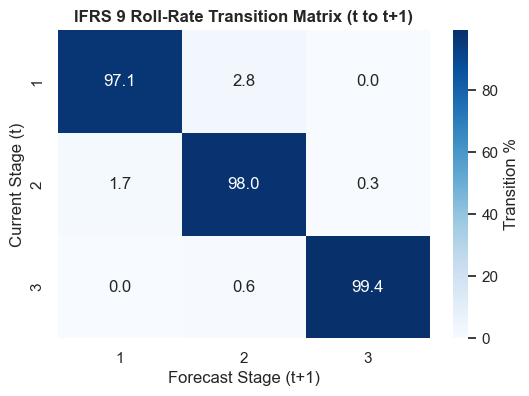

--- STAGE MOVEMENT HEADCOUNT & VOLUME SUMMARY ---


,Stage Transition Direction,Facility Count,Migrated EAD ($M)
0,Stage 1 -> Stage 2 (Deterioration),1262,"1,081.80"
1,Stage 2 -> Stage 3 (Default),13,6.58
2,Stage 2 -> Stage 1 (Cure),81,63.43
3,Stage 3 -> Stage 2 (Recovery),3,0.29


In [5]:
# ------------------------------------------------------------------------------
# 1. IFRS 9 STAGING CLASSIFICATION FUNCTION
# ------------------------------------------------------------------------------
def assign_stage(row, crg_col, dpd_col):
    """
    Classifies facilities into IFRS 9 Staging categories:
    - Stage 3 (Credit Impaired): DPD >= 90 or CRG == 24 (Default / UTP).
    - Stage 2 (Underperforming / SICR): DPD >= 30 OR rating downgrade >= 3 notches from origination.
    - Stage 1 (Performing): Low credit risk, DPD < 30, rating downgrade < 3 notches.
    """
    if row[dpd_col] >= 90 or row[crg_col] == 24:
        return 3
    if row[dpd_col] >= 30 or (row[crg_col] - row['CRG_Orig']) >= 3:
        return 2
    return 1  ## This represents improvement i.e. curing i.e. If a borrower pays down arrears (DPD < 30) """AND""" their risk grade improves such that CRG_Current - CRG_Orig < 3, it fails the Stage 3 and Stage 2 checks and automatically returns 1 (Stage 1).

# Execute staging logic dynamically across current month (t), forecast t+1, and forecast t+2
df['Stage_t'] = df.apply(lambda x: assign_stage(x, 'CRG_t', 'DPD_t'), axis=1)
df['Stage_t1'] = df.apply(lambda x: assign_stage(x, 'CRG_t1', 'DPD_t1'), axis=1)
df['Stage_t2'] = df.apply(lambda x: assign_stage(x, 'CRG_t2', 'DPD_t2'), axis=1)

# ------------------------------------------------------------------------------
# 2. ROLL-RATE TRANSITION MATRIX & HEADCOUNT MOVEMENTS
# ------------------------------------------------------------------------------
# Calculate cross-tabulation matrix showing percentage migration between Stage t and Stage t+1
roll_rate_matrix = pd.crosstab(df['Stage_t'], df['Stage_t1'], normalize='index') * 100

# Compute specific directional facility transition counts for executive management reporting
s1_to_s2 = ((df['Stage_t'] == 1) & (df['Stage_t1'] == 2)).sum()
s2_to_s3 = ((df['Stage_t'] == 2) & (df['Stage_t1'] == 3)).sum()
s2_to_s1_cures = ((df['Stage_t'] == 2) & (df['Stage_t1'] == 1)).sum()
s3_to_s2_cures = ((df['Stage_t'] == 3) & (df['Stage_t1'] == 2)).sum()

# Compile Stage Movement Summary Table
movement_summary = pd.DataFrame({
    'Stage Transition Direction': [
        'Stage 1 -> Stage 2 (Deterioration)', 
        'Stage 2 -> Stage 3 (Default)', 
        'Stage 2 -> Stage 1 (Cure)', 
        'Stage 3 -> Stage 2 (Recovery)'
    ],
    'Facility Count': [s1_to_s2, s2_to_s3, s2_to_s1_cures, s3_to_s2_cures],
    'Migrated EAD ($M)': [
        df[(df['Stage_t'] == 1) & (df['Stage_t1'] == 2)]['EAD'].sum() / 1e6,
        df[(df['Stage_t'] == 2) & (df['Stage_t1'] == 3)]['EAD'].sum() / 1e6,
        df[(df['Stage_t'] == 2) & (df['Stage_t1'] == 1)]['EAD'].sum() / 1e6,
        df[(df['Stage_t'] == 3) & (df['Stage_t1'] == 2)]['EAD'].sum() / 1e6
    ]
})

# Render Seaborn Heatmap for Roll-Rate Transition Matrix
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(roll_rate_matrix, annot=True, fmt=".1f", cmap="Blues", cbar_kws={'label': 'Transition %'}, ax=ax)
ax.set_title("IFRS 9 Roll-Rate Transition Matrix (t to t+1)", fontweight='bold')
ax.set_xlabel("Forecast Stage (t+1)")
ax.set_ylabel("Current Stage (t)")
plt.show()

print("--- STAGE MOVEMENT HEADCOUNT & VOLUME SUMMARY ---")
display(movement_summary.style.format({'Migrated EAD ($M)': "{:,.2f}"}))

## Time Periods (t, t+1, t+2) vs. IFRS 9 Stages (1, 2, 3)

| Metric | What It Represents | Examples |
|----------|----------|----------|
| **Time Horizon (t, t+1, t+2)** | Forecast timeline snapshots showing when the portfolio is measured. | t = Current Period (Today), t+1 = Forecast Year 1, t+2 = Forecast Year 2 |
| **IFRS 9 Stage (1, 2, 3)** | Credit risk bucket assigned to a facility at a specific point in time. | Stage 1 = Performing (12-Month ECL), Stage 2 = Significant Increase in Credit Risk (Lifetime ECL), Stage 3 = Credit Impaired / Default (Lifetime ECL) |

### Cell 5: Multi-Period Scenario ECL & Overlay Governance

In [6]:
# Macroeconomic FORECAST scenario PD multipliers approved by Risk Committee:
# These are not probabilities. These below are risk multipliers.
# - Base: 1.00x (Baseline macro expectations)
# - Upside: 0.85x (Favorable economic conditions reduce PDs)
# - Downside: 1.45x (Severe macro stress increases PDs by 45%)
macro_scalars = {'Base': 1.00, 'Upside': 0.85, 'Downside': 1.45}

def calculate_ecl(row, period_prefix):
    """
    Calculates facility-level Expected Credit Loss (ECL):
    - Maps CRG to TTC PD via PD_MASTER_SCALE lookup table.
    - Scales PD across Base, Upside, and Downside macro scenarios.
    - Applies Effective Interest Rate (EIR) discounting over remaining loan term.
    - Stage 1: 12-Month ECL discounted via 1 / (1 + EIR).
    - Stage 2 & 3: Lifetime ECL discounted via continuous annuity factor.
    - Applies explicit +8% Climate Risk overlay to CRE and Agribusiness.
    """
    crg = row[f'CRG_{period_prefix}']
    stage = row[f'Stage_{period_prefix}']
    
    # 1. Fetch baseline PD from approved Master Scale lookup table
    base_pd = PD_MASTER_SCALE[crg]
    
    ecl_scenarios = {}
    for sc, scalar in macro_scalars.items():
        # Scale PD by macroeconomic factor (capped at 100%)
        scen_pd = min(base_pd * scalar, 1.0)
        
        # Calculate EIR discount factor based on stage requirement
        # Stage 1: 12-Month ECL (Discounted over 1 year)
        # Stage 2 & 3: Lifetime ECL (Discounted continuously across full remaining loan term)
        discount_factor = 1 / (1 + row['EIR']) if stage == 1 else (1 - (1 + row['EIR'])**(-row['Term_Years'])) / row['EIR']
        # In current time t, or in forecasts t1 and t2, the loan could be in Stage 1, Stage 2 or Stage 3.
        
        # Calculate unweighted scenario ECL
        ecl_scenarios[sc] = row['EAD'] * scen_pd * row['Historical_LGD'] * discount_factor # ECL = EAD * pd * LGD
        
    # 2. Calculate Probability-Weighted Model ECL across economic paths
    model_ecl = sum(ecl_scenarios[sc] * MACRO_WEIGHTS[sc] for sc in macro_scalars) # SUM(Scenario ECL * probability given in macro_scalars)
    
    # 3. Apply Climate Risk Post-Model Adjustment (PMA) overlay (8% top-up for vulnerable sectors)
    climate_pma = model_ecl * 0.08 if row['Sector'] in ['Commercial Real Estate', 'CRE_IPRE', 'Agribusiness'] else 0.0
    
    # Return Pandas Series containing full component and scenario sensitivity breakdown
    return pd.Series([
        model_ecl, 
        climate_pma, 
        model_ecl + climate_pma, 
        ecl_scenarios['Base'], 
        ecl_scenarios['Upside'], 
        ecl_scenarios['Downside']
    ])

# Compute multi-period ECL outputs for Current (t), Forecast Year 1 (t+1), and Forecast Year 2 (t+2)
df[['Model_ECL_t', 'Climate_PMA_t', 'ECL_t', 'ECL_100_Base_t', 'ECL_100_Upside_t', 'ECL_100_Downside_t']] = df.apply(lambda r: calculate_ecl(r, 't'), axis=1)
df[['Model_ECL_t1', 'Climate_PMA_t1', 'ECL_t1', 'ECL_100_Base_t1', 'ECL_100_Upside_t1', 'ECL_100_Downside_t1']] = df.apply(lambda r: calculate_ecl(r, 't1'), axis=1)
df[['Model_ECL_t2', 'Climate_PMA_t2', 'ECL_t2', 'ECL_100_Base_t2', 'ECL_100_Upside_t2', 'ECL_100_Downside_t2']] = df.apply(lambda r: calculate_ecl(r, 't2'), axis=1)
# t1, t2 are forecasts, not Stage 2 nor Stage 3.
# ECL_100_Downside means Forces the Downside probability weight to 100% (and Base/Upside to 0%) by using only the Downside macro multiplier ($1.45\times$) and ignores MACRO_WEIGHTS entirely.
# ECL_100_Downside = EAD × (PD × 1.45) × LGD × Discount Factor

# Build Executive Overlay Governance Summary Table
overlay_governance = pd.DataFrame({
    'Provision Component / Scenario': [
        'Modelled ECL (Base + Scenario Weighted)', 
        'Climate Risk Overlay', 
        'Total Balance Sheet Provision Reserve',
        '100% Base Scenario Sensitivity',
        '100% Upside Scenario Sensitivity',
        '100% Downside Scenario Sensitivity'
    ],
    'Period t ($M)': [
        df['Model_ECL_t'].sum() / 1e6, 
        df['Climate_PMA_t'].sum() / 1e6, 
        df['ECL_t'].sum() / 1e6,
        df['ECL_100_Base_t'].sum() / 1e6,
        df['ECL_100_Upside_t'].sum() / 1e6,
        df['ECL_100_Downside_t'].sum() / 1e6
    ],
    'Period t+1 ($M)': [
        df['Model_ECL_t1'].sum() / 1e6, 
        df['Climate_PMA_t1'].sum() / 1e6, 
        df['ECL_t1'].sum() / 1e6,
        df['ECL_100_Base_t1'].sum() / 1e6,
        df['ECL_100_Upside_t1'].sum() / 1e6,
        df['ECL_100_Downside_t1'].sum() / 1e6
    ]
})

print("--- OVERLAY GOVERNANCE & PMA BREAKDOWN ---")
display(overlay_governance.style.format({'Period t ($M)': "${:,.2f}", 'Period t+1 ($M)': "${:,.2f}"}))

--- OVERLAY GOVERNANCE & PMA BREAKDOWN ---


,Provision Component / Scenario,Period t ($M),Period t+1 ($M)
0,Modelled ECL (Base + Scenario Weighted),"$1,496.01","$1,835.83"
1,Climate Risk Overlay,$63.80,$77.42
2,Total Balance Sheet Provision Reserve,"$1,559.81","$1,913.26"
3,100% Base Scenario Sensitivity,"$1,293.46","$1,593.88"
4,100% Upside Scenario Sensitivity,"$1,099.44","$1,354.80"
5,100% Downside Scenario Sensitivity,"$1,848.35","$2,258.53"


### Cell 6: Provisioning Expense, Coverage Ratios & Roll-Forward

In [7]:
# ------------------------------------------------------------------------------
# 1. P&L VARIANCE ATTRIBUTION DECOMPOSITION
# ------------------------------------------------------------------------------

# Simulate 10% new originations in current period t to calculate Volume Effect properly.
df['Is_New_Loan'] = np.random.choice([0, 1], size=len(df), p=[0.90, 0.10])

# Prior_ECL is $0 for new loans, and realistic historical ECL for existing loans
# Uses df['CRG_t'].map(PD_MASTER_SCALE) to lookup TTC PD dynamically and prevent KeyError: 'TTC_PD'
df['Prior_ECL'] = np.where(
    df['Is_New_Loan'] == 1, 
    0.0, 
    df['EAD'] * (df['CRG_t'].map(PD_MASTER_SCALE) * np.random.uniform(0.8, 1.1, len(df))) * df['Historical_LGD']  
)
# The prior_pd is calculated with a variation using random function so that its differnt from current PD.
# EAD and historical_LGD remains same in prior period for sake of simplicity.
# Prior-period Expected Credit Loss (ECL) approximation: Prior_ECL = EAD_t × PD_(t-1) × LGD_t × Scalar

# Calculate net ECL = Closing ECL_t - Opening Prior_ECL
df['Prior_ECL'] = df['Prior_ECL'].fillna(0)
df['Provisioning Expense'] = df['ECL_t'] - df['Prior_ECL']

# Decompose P&L variance drivers using explicit Is_New_Loan flag:
# - Volume Effect: ECL movement driven by brand new facility originations (Is_New_Loan == 1)
# - Migration Effect: ECL movement driven by rating downgrades or stage transfers on existing loans (Is_New_Loan == 0)
df['Volume_Effect'] = np.where(df['Is_New_Loan'] == 1, df['ECL_t'], 0.0)
df['Migration_Effect'] = np.where(df['Is_New_Loan'] == 0, df['ECL_t'] - df['Prior_ECL'], 0.0)

# ------------------------------------------------------------------------------
# P&L VARIANCE ATTRIBUTION SUMMARY TABLE
# ------------------------------------------------------------------------------
pl_variance_table = pd.DataFrame({
    'P&L Movement Driver': [
        'Opening Provision Reserve (Prior_ECL)',
        '(+) New Volume Effect (New Originations)',
        '(+/-) Risk Migration Effect (Rating & Stage Shifts)',
        'Closing Provision Reserve (ECL_t)',
        'Net Provisioning Expense'
    ],
    'Amount ($M)': [
        df['Prior_ECL'].sum() / 1e6,
        df['Volume_Effect'].sum() / 1e6,
        df['Migration_Effect'].sum() / 1e6,
        df['ECL_t'].sum() / 1e6,
        df['Provisioning Expense'].sum() / 1e6
    ]
})

# ------------------------------------------------------------------------------
# 2. PROVISION COVERAGE RATIOS ACROSS STAGES
# ------------------------------------------------------------------------------
# Calculate Provision Coverage Ratio (%): Coverage = (Total ECL Reserve / Total EAD Exposure) * 100
cov_total = (df['ECL_t'].sum() / df['EAD'].sum()) * 100
cov_s1 = (df[df['Stage_t'] == 1]['ECL_t'].sum() / df[df['Stage_t'] == 1]['EAD'].sum()) * 100
cov_s2 = (df[df['Stage_t'] == 2]['ECL_t'].sum() / df[df['Stage_t'] == 2]['EAD'].sum()) * 100
cov_s3 = (df[df['Stage_t'] == 3]['ECL_t'].sum() / df[df['Stage_t'] == 3]['EAD'].sum()) * 100

# Build Provision Coverage Summary Table
coverage_table = pd.DataFrame({
    'Portfolio Stage': ['Total Portfolio', 'Stage 1 (Performing)', 'Stage 2 (SICR)', 'Stage 3 (Default)'],
    'EAD ($M)': [
        df['EAD'].sum() / 1e6, 
        df[df['Stage_t'] == 1]['EAD'].sum() / 1e6, 
        df[df['Stage_t'] == 2]['EAD'].sum() / 1e6, 
        df[df['Stage_t'] == 3]['EAD'].sum() / 1e6
    ],
    'ECL Reserve ($M)': [
        df['ECL_t'].sum() / 1e6, 
        df[df['Stage_t'] == 1]['ECL_t'].sum() / 1e6, 
        df[df['Stage_t'] == 2]['ECL_t'].sum() / 1e6, 
        df[df['Stage_t'] == 3]['ECL_t'].sum() / 1e6
    ],
    'Coverage Ratio (%)': [cov_total, cov_s1, cov_s2, cov_s3]
})

# Calculate headline annualized Portfolio Loan Loss Rate in basis points (bps)
# Formula: Loan Loss Rate (bps) = (Total Provisioning Expense / Total EAD) * 10,000
loan_loss_rate_bps = (df['Provisioning Expense'].sum() / df['EAD'].sum()) * 10000 # Portfolio Loss Rate (bps)= (Closing ECL − Opening ECL) / Total EAD ​×10,000

print("--- EXECUTIVE PROVISION COVERAGE RATIO ANALYSIS ---")
display(coverage_table.style.format({'EAD ($M)': "${:,.2f}", 'ECL Reserve ($M)': "${:,.2f}", 'Coverage Ratio (%)': "{:.2f}%"}))

print("--- EXECUTIVE P&L VARIANCE ATTRIBUTION SUMMARY ---")
display(pl_variance_table.style.format({'Amount ($M)': "${:,.2f}"}))

print(f"\nAnnualized Portfolio Loan Loss Rate: {loan_loss_rate_bps:.1f} bps")

--- EXECUTIVE PROVISION COVERAGE RATIO ANALYSIS ---


,Portfolio Stage,EAD ($M),ECL Reserve ($M),Coverage Ratio (%)
0,Total Portfolio,"$40,593.30","$1,559.81",3.84%
1,Stage 1 (Performing),"$36,430.06",$816.77,2.24%
2,Stage 2 (SICR),"$3,773.11",$651.89,17.28%
3,Stage 3 (Default),$390.13,$91.15,23.36%


--- EXECUTIVE P&L VARIANCE ATTRIBUTION SUMMARY ---


,P&L Movement Driver,Amount ($M)
0,Opening Provision Reserve (Prior_ECL),$746.24
1,(+) New Volume Effect (New Originations),$151.97
2,(+/-) Risk Migration Effect (Rating & Stage Shifts),$661.60
3,Closing Provision Reserve (ECL_t),"$1,559.81"
4,Net Provisioning Expense,$813.57



Annualized Portfolio Loan Loss Rate: 200.4 bps


### Cell 7: Portfolio Analytics (Sector Stress, Watchlist & Concentration)

In [8]:
# ------------------------------------------------------------------------------
# 1. SECTOR STRESS RATIOS & COVERAGE ANALYSIS
# ------------------------------------------------------------------------------
# Aggregate EAD, ECL, and Stressed EAD (Stage 2 + Stage 3) by Industry Sector
sector_analytics = df.groupby("Sector").agg(
    Total_EAD=("EAD", "sum"),
    Total_ECL=("ECL_t", "sum"),
    Stressed_EAD=("EAD", lambda x: x[df.loc[x.index, "Stage_t"].isin([2, 3])].sum())
).reset_index()

# Calculate Sector Metrics:
# - EAD Share (%): Percentage of total bank loan book in this sector => EAD Share % = Sector EAD / Total Portfolio EAD
# - Sector Coverage (%): ECL Reserve or ECL Allowance / Total Sector EAD
# - Sector Stress Ratio (%): (Stage 2 EAD + Stage 3 EAD) / Total Sector EAD
sector_analytics["EAD_Share_%"] = (sector_analytics["Total_EAD"] / df['EAD'].sum()) * 100
sector_analytics["Sector_Coverage_%"] = (sector_analytics["Total_ECL"] / sector_analytics["Total_EAD"]) * 100
sector_analytics["Sector_Stress_Ratio_%"] = (sector_analytics["Stressed_EAD"] / sector_analytics["Total_EAD"]) * 100

# Calculate Herfindahl-Hirschman Index (HHI) for Sector Concentration Risk
# Formula: HHI = Sum of squared market shares (%^2). HHI < 1,500 indicates a well-diversified book.
hhi_score = (sector_analytics["EAD_Share_%"]**2).sum()

# ------------------------------------------------------------------------------
# 2. WATCHLIST REPORTING & TOP 5 BORROWER EXPOSURES
# ------------------------------------------------------------------------------
# Filter Watchlist facilities (CRG 17 to 23)
watchlist_df = df[(df['CRG_t'] >= 17) & (df['CRG_t'] <= 23)]
watchlist_ead_share = (watchlist_df['EAD'].sum() / df['EAD'].sum()) * 100

# Extract Top 5 single-name commercial borrower exposures by EAD
top_5 = df.nlargest(5, 'EAD')[['Facility_ID', 'Sector', 'CRG_t', 'Stage_t', 'EAD', 'ECL_t']]

print("--- SECTOR STRESS & COVERAGE ANALYSIS ---")
display(sector_analytics[['Sector', 'Total_EAD', 'EAD_Share_%', 'Sector_Coverage_%', 'Sector_Stress_Ratio_%']].style.format({
    'Total_EAD': "${:,.0f}", 'EAD_Share_%': "{:.1f}%", 'Sector_Coverage_%': "{:.2f}%", 'Sector_Stress_Ratio_%': "{:.2f}%"
}))

print(f"Sector Herfindahl-Hirschman Index (HHI): {hhi_score:.0f} (Well-Diversified)")
print(f"Total Watchlist Portfolio Share (CRG 17-23): {watchlist_ead_share:.2f}%")

print("\n--- TOP 5 SINGLE BORROWER EXPOSURES ---")
display(top_5.style.format({'EAD': "${:,.2f}", 'ECL_t': "${:,.2f}"}))

--- SECTOR STRESS & COVERAGE ANALYSIS ---


,Sector,Total_EAD,EAD_Share_%,Sector_Coverage_%,Sector_Stress_Ratio_%
0,Agribusiness,"$6,327,445,701",15.6%,4.11%,10.00%
1,Commercial Real Estate,"$14,903,748,743",36.7%,4.03%,10.27%
2,Corporate,"$11,259,856,883",27.7%,3.56%,10.29%
3,SME Retail,"$8,102,243,912",20.0%,3.67%,10.39%


Sector Herfindahl-Hirschman Index (HHI): 2759 (Well-Diversified)
Total Watchlist Portfolio Share (CRG 17-23): 16.15%

--- TOP 5 SINGLE BORROWER EXPOSURES ---


,Facility_ID,Sector,CRG_t,Stage_t,EAD,ECL_t
47197,BUS_047198,Commercial Real Estate,2,1,"$120,799,647.82","$23,580.54"
49264,BUS_049265,Agribusiness,14,1,"$74,620,909.29","$2,039,318.92"
21732,BUS_021733,Agribusiness,4,1,"$58,250,218.36","$23,387.21"
16710,BUS_016711,Corporate,3,1,"$41,508,940.01","$11,847.25"
8701,BUS_008702,SME Retail,6,1,"$41,452,294.45","$42,652.85"


### Cell 8: IFRS 9 Forecast Disclosures & CSV Data Mart Export

In [9]:
# ------------------------------------------------------------------------------
# 1. IFRS 9 MULTI-PERIOD FORECAST MATRIX & INTEREST UNWINDING
# ------------------------------------------------------------------------------
# Build multi-period executive forecast matrix comparing Probability-Weighted vs 100% Scenarios
forecast_matrix = pd.DataFrame({
    'Reporting Horizon': ['Current Period (t)', 'Forecast Year 1 (t+1)', 'Forecast Year 2 (t+2)'],
    'Total Modelled ECL ($M)': [
        df['ECL_t'].sum() / 1e6, 
        df['ECL_t1'].sum() / 1e6, 
        df['ECL_t2'].sum() / 1e6
    ],
    '100% Base Sensitivity ($M)': [
        df['ECL_100_Base_t'].sum() / 1e6, 
        df['ECL_100_Base_t1'].sum() / 1e6, 
        df['ECL_100_Base_t2'].sum() / 1e6
    ],
    '100% Upside Sensitivity ($M)': [
        df['ECL_100_Upside_t'].sum() / 1e6, 
        df['ECL_100_Upside_t1'].sum() / 1e6, 
        df['ECL_100_Upside_t2'].sum() / 1e6
    ],
    '100% Downside Stress ECL ($M)': [
        df['ECL_100_Downside_t'].sum() / 1e6, 
        df['ECL_100_Downside_t1'].sum() / 1e6, 
        df['ECL_100_Downside_t2'].sum() / 1e6
    ],
    'Portfolio Loss Rate (bps)': [
        (df['ECL_t'].sum() - df['Prior_ECL'].sum()) / df['EAD'].sum() * 10000,
        (df['ECL_t1'].sum() - df['ECL_t'].sum()) / df['EAD'].sum() * 10000,
        (df['ECL_t2'].sum() - df['ECL_t1'].sum()) / df['EAD'].sum() * 10000
    ]
})

# Calculate Current Loans in Stage 3: Net Interest Income Unwinding
# Under IFRS 9, interest income for Stage 3 defaulted loans is recognized on Net Carrying Amount:
# Formula: Interest Unwind = (EAD - ECL) * EIR    # (Gross Carrying Amount − Loss Allowance) * Effective Interest Rate
stage3_df = df[df['Stage_t'] == 3]
interest_unwind = ((stage3_df['EAD'] - stage3_df['ECL_t']) * stage3_df['EIR']).sum()

# Facility-level Stage 3 Net Interest Unwind ($) for each individual Stage 3 loan
df['Stage3_Interest_Unwind_t'] = np.where(
    df['Stage_t'] == 3, 
    (df['EAD'] - df['ECL_t']) * df['EIR'], 
    0.0
) 

print("--- IFRS 9 MULTI-PERIOD ECL FORECAST DISCLOSURE ---")
display(forecast_matrix.style.format({
    'Total Modelled ECL ($M)': "${:,.2f}M", 
    '100% Base Sensitivity ($M)': "${:,.2f}M",
    '100% Upside Sensitivity ($M)': "${:,.2f}M",
    '100% Downside Stress ECL ($M)': "${:,.2f}M", 
    'Portfolio Loss Rate (bps)': "{:.1f} bps"
}))

print(f"\nStage 3 Net Interest Unwinding (Recognized on Net Carrying Amount): ${interest_unwind:,.2f}")

--- IFRS 9 MULTI-PERIOD ECL FORECAST DISCLOSURE ---


,Reporting Horizon,Total Modelled ECL ($M),100% Base Sensitivity ($M),100% Upside Sensitivity ($M),100% Downside Stress ECL ($M),Portfolio Loss Rate (bps)
0,Current Period (t),"$1,559.81M","$1,293.46M","$1,099.44M","$1,848.35M",200.4 bps
1,Forecast Year 1 (t+1),"$1,913.26M","$1,593.88M","$1,354.80M","$2,258.53M",87.1 bps
2,Forecast Year 2 (t+2),"$1,942.60M","$1,619.11M","$1,376.24M","$2,290.87M",7.2 bps



Stage 3 Net Interest Unwinding (Recognized on Net Carrying Amount): $19,589,486.47


In [10]:
# ------------------------------------------------------------------------------
# DATA MART PRE-EXPORT ENHANCEMENTS FOR POWER BI
# ------------------------------------------------------------------------------
# 1. Descriptive Human-Readable Stage Labels
stage_labels = {1: 'Stage 1 (Performing)', 2: 'Stage 2 (SICR)', 3: 'Stage 3 (Default)'}
df['Stage_Name_t'] = df['Stage_t'].map(stage_labels)
df['Stage_Name_t1'] = df['Stage_t1'].map(stage_labels)

# 2. Executive Customer Risk Grade (CRG) Risk Bands
def assign_crg_band(crg):
    if crg <= 10:   return '1-10 Investment Grade'
    elif crg <= 16: return '11-16 Satisfactory'
    elif crg <= 23: return '17-23 Watchlist / Weak'
    else:           return '24 Default / Impaired'

df['CRG_Band_t'] = df['CRG_t'].apply(assign_crg_band)

# 3. Stage Transition Label (t to t+1)
def assign_transition_label(row):
    s_t, s_t1 = row['Stage_t'], row['Stage_t1']
    if s_t == 1 and s_t1 == 2:   return 'S1 -> S2 (Deterioration)'
    elif s_t == 2 and s_t1 == 3: return 'S2 -> S3 (Default)'
    elif s_t == 2 and s_t1 == 1: return 'S2 -> S1 (Cure)'
    elif s_t == 3 and s_t1 == 2: return 'S3 -> S2 (Recovery)'
    else:                        return 'Unchanged'

df['Stage_Transition_t_t1'] = df.apply(assign_transition_label, axis=1)

# 4. Stressed EAD Flag (Stage 2 & Stage 3)
df['Is_Stressed_EAD'] = np.where(df['Stage_t'].isin([2, 3]), 1, 0)

# 5. GL Reconciliation Break Flag
df['Is_GL_Break'] = np.where(df['GL_Variance'].abs() > 0.01, 1, 0)

# 6. Primary Reference ECL & Overlay Alias
df['Final_ECL'] = df['ECL_t']
df['Model_ECL'] = df['Model_ECL_t']
df['Climate_Overlay'] = df['Climate_PMA_t']

# Export enriched dataset to CSV
df.to_csv("Master_Provisioning_Output.csv", index=False)
print("Data Mart exported successfully with all required Power BI dimensions!")

Data Mart exported successfully with all required Power BI dimensions!


In [11]:
# # ------------------------------------------------------------------------------
# # OPTIONAL : EXPORT TABLE B SUMMARY TABLES TO CSV
# # ------------------------------------------------------------------------------
# overlay_governance.to_csv("summary_overlay_governance.csv", index=False)
# pl_variance_table.to_csv("summary_pl_variance_attribution.csv", index=False)
# coverage_table.to_csv("summary_provision_coverage.csv", index=False)
# forecast_matrix.to_csv("summary_ifrs9_multi_period_forecast.csv", index=False)
# exception_summary.to_csv("summary_GL_exceptions.csv", index=False)

# print("Table B summary files exported successfully!")